In [86]:
import matplotlib.pyplot as plt
from collections import deque
import heapq
import math
from matplotlib.colors import ListedColormap #do kolorow

# Mapa zapisana tekstowo: "." – pole dostępne (0), "#" – przeszkoda (1)
MAPA = [
    "..#....#......",
    "#...#..#....##",
    "..........#..#",
    ".......###....",
    "...#...#......",
    ".#...##.#.....",
    "###...#......#",
    "......##.....#",
    "#.#..#.#..####",
    "#.##..........",
]

grid = [[1 if ch == "#" else 0 for ch in wiersz] for wiersz in MAPA]

start = (0, 0)
goal = (9, 13)

rows = len(grid)
cols = len(grid[0])

print("Rozmiar planszy:", rows, "x", cols)
print("Start:", start)
print("Cel:", goal)

def draw_grid(path=None, visited=None, title="Plansza"):
    kolory_terenu = {0: 0, 1: 1, 3: 2, 5: 3}

    img = [[kolory_terenu[cell] for cell in row] for row in grid]

    cmap = ListedColormap([
        "white",     # zwykłe pole
        "black",     # przeszkoda
        "#F5E6A7",   # piasek - kremowy żółty
        "#245C36"    # bagno - ciemnozielony
    ])

    plt.figure(figsize=(10, 7))
    plt.imshow(img, cmap=cmap, vmin=-0.5, vmax=3.5, origin="upper")

    if visited:
        vr = [p[0] for p in visited]
        vc = [p[1] for p in visited]

        sc = plt.scatter(
            vc, vr,
            c=range(len(visited)),
            cmap="viridis",
            s=110,
            alpha=0.85,
            label="odwiedzone"
        )

        plt.colorbar(sc, label="kolejność odwiedzin", shrink=0.8)

    if path:
        pr = [p[0] for p in path]
        pc = [p[1] for p in path]

        plt.plot(
            pc, pr,
            color="red",
            marker="o",
            linewidth=3,
            label="ścieżka"
        )

    plt.scatter(start[1], start[0], s=180, marker="s",
                color="orange", label="start")

    plt.scatter(goal[1], goal[0], s=250, marker="*",
                color="magenta", label="cel")

    plt.xticks(range(cols))
    plt.yticks(range(rows))
    plt.grid(True)
    plt.title(title)
    plt.legend(loc="upper left", bbox_to_anchor=(1.25, 1))
    plt.show()



Rozmiar planszy: 10 x 14
Start: (0, 0)
Cel: (9, 13)


In [ ]:
################################################## ZADANIE 1

DFS - długość ścieżki: 56
DFS - odwiedzone stany: 88


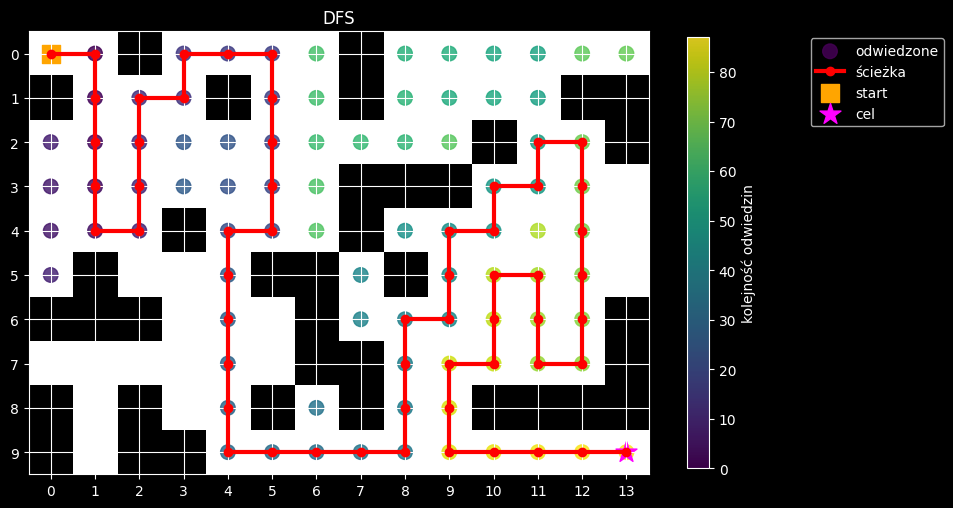

In [87]:
def get_neighbors(state):
    r, c = state

    moves = [
        (0, 1),   # prawo
        (0, -1),  # lewo
        (1, 0),   # dół
        (-1, 0),  # góra
    ]

    neighbors = []

    for dr, dc in moves:
        nr, nc = r + dr, c + dc

        if 0 <= nr < rows and 0 <= nc < cols:
            if grid[nr][nc] == 0:
                neighbors.append((nr, nc))

    return neighbors


def reconstruct_path(parent, goal):
    path = []
    current = goal

    while current is not None:
        path.append(current)
        current = parent[current]

    path.reverse()
    return path

def dfs(start, goal):
    # Na stosie trzymamy pary (stan, rodzic). Rodzica zapisujemy dopiero wtedy,
    # gdy DFS faktycznie wchodzi do stanu – dzięki temu narysowana ścieżka
    # jest drogą, którą algorytm naprawdę przeszedł.
    stack = [(start, None)]
    visited = set()
    parent = {}
    visit_order = []

    while stack:
        current, current_parent = stack.pop()

        if current in visited:
            continue

        visited.add(current)
        parent[current] = current_parent
        visit_order.append(current)

        if current == goal:
            return reconstruct_path(parent, goal), visit_order

        for neighbor in get_neighbors(current):
            if neighbor not in visited:
                stack.append((neighbor, current))

    return None, visit_order


dfs_path, dfs_visited = dfs(start, goal)

print("DFS - długość ścieżki:", len(dfs_path) - 1)
print("DFS - odwiedzone stany:", len(dfs_visited))

draw_grid(dfs_path, dfs_visited, "DFS")


In [9]:
"""
1. Czy DFS znajdzie inną ścieżkę,
Tak. DFS wykonuje ruchy w kolejności jakie zostały podane (wpierw próbuje góra, później lewo itd.).
2. Czy zmieni się liczba odwiedzonych stanów.
Tak. DFS dokładnie sprawdza daną ściężkę jaką obierze. Zmieniając kolejność ruchów zmienia się również kolejność sprawdzania ścieżek (w tym więcej błędnych scieżek).
"""

SyntaxError: invalid syntax (2394846599.py, line 1)

In [17]:
################################################## ZADANIE 2

BFS - długość ścieżki: 22
BFS - odwiedzone stany: 104
BFS - ścieżka: [(0, 0), (0, 1), (0, 2), (0, 3), (0, 4), (0, 5), (0, 6), (0, 7), (0, 8), (0, 9), (0, 10), (0, 11), (0, 12), (0, 13), (1, 13), (2, 13), (3, 13), (4, 13), (5, 13), (6, 13), (7, 13), (8, 13), (9, 13)]


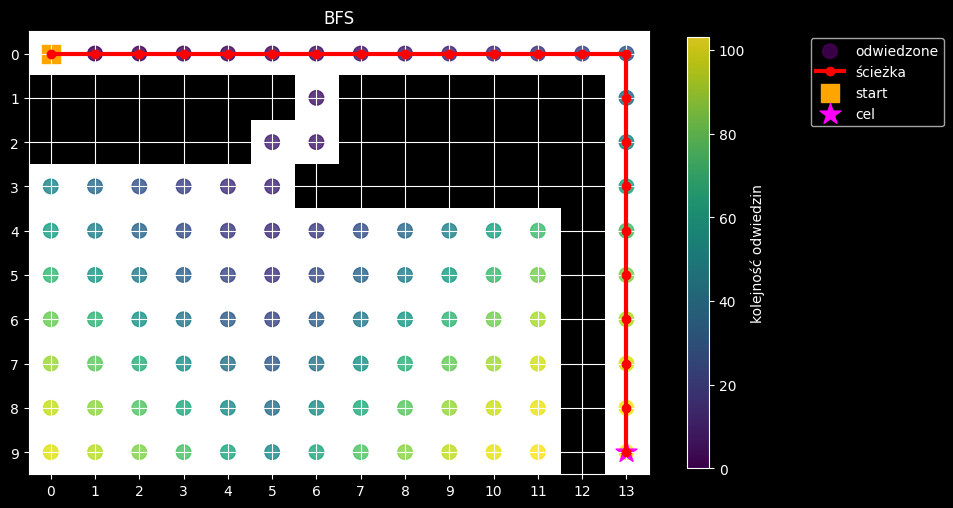

A* - koszt: 22
A* - odwiedzone stany: 25


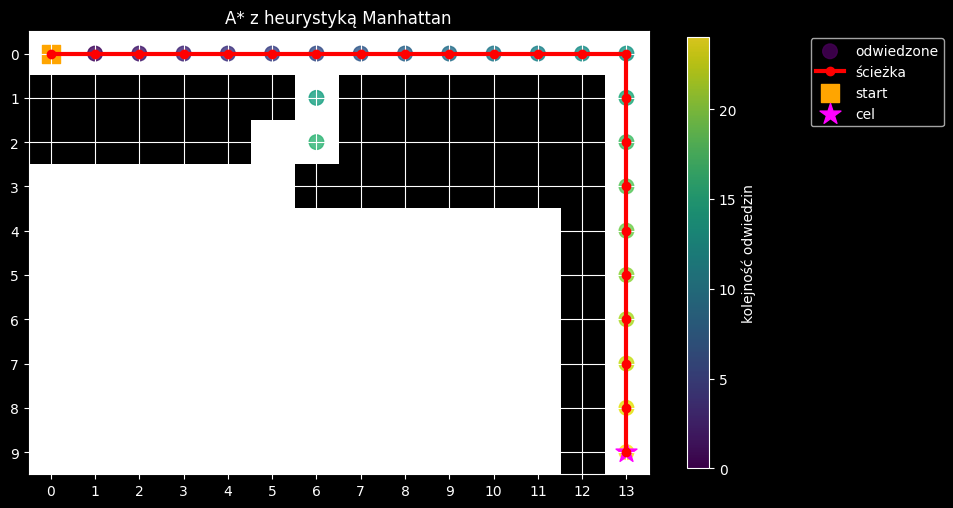

In [70]:

# Mapa zapisana tekstowo: "." – pole dostępne (0), "#" – przeszkoda (1)
MAPA = [
    "..............",
    "######.######.",
    "#####..######.",
    "......#######.",
    "............#.",
    "............#.",
    "............#.",
    "............#.",
    "............#.",
    "............#."
]

grid = [[1 if ch == "#" else 0 for ch in wiersz] for wiersz in MAPA]

start = (0, 0)
goal = (9, 13)

rows = len(grid)
cols = len(grid[0])

################################################## RESET

def get_neighbors(state):
    r, c = state

    moves = [
        (-1, 0),  # góra
        (1, 0),   # dół
        (0, -1),  # lewo
        (0, 1),   # prawo
    ]

    neighbors = []

    for dr, dc in moves:
        nr, nc = r + dr, c + dc

        if 0 <= nr < rows and 0 <= nc < cols:
            if grid[nr][nc] == 0:
                neighbors.append((nr, nc))

    return neighbors

################################################## RESET


def reconstruct_path(parent, goal):
    path = []
    current = goal

    while current is not None:
        path.append(current)
        current = parent[current]

    path.reverse()
    return path


def bfs(start, goal):
    queue = deque([start])
    visited = {start}
    parent = {start: None}
    visit_order = []

    while queue:
        current = queue.popleft()
        visit_order.append(current)

        if current == goal:
            return reconstruct_path(parent, goal), visit_order

        for neighbor in get_neighbors(current):
            if neighbor not in visited:
                visited.add(neighbor)
                parent[neighbor] = current
                queue.append(neighbor)

    return None, visit_order


bfs_path, bfs_visited = bfs(start, goal)

print("BFS - długość ścieżki:", len(bfs_path) - 1)
print("BFS - odwiedzone stany:", len(bfs_visited))
print("BFS - ścieżka:", bfs_path)

draw_grid(bfs_path, bfs_visited, "BFS")

def manhattan(a, b):
    return abs(a[0] - b[0]) + abs(a[1] - b[1])

def astar(start, goal, heuristic=manhattan):
    open_heap = []
    heapq.heappush(open_heap, (heuristic(start, goal), start))

    g_score = {start: 0}
    parent = {start: None}
    closed = set()
    visit_order = []

    while open_heap:
        _, current = heapq.heappop(open_heap)

        if current in closed:
            continue

        closed.add(current)
        visit_order.append(current)

        if current == goal:
            return reconstruct_path(parent, goal), visit_order, g_score[goal]

        for neighbor in get_neighbors(current):
            if neighbor in closed:
                continue  # stan zamknięty – nie zmieniamy już jego rodzica ani kosztu

            tentative_g = g_score[current] + 1

            if tentative_g < g_score.get(neighbor, float("inf")):
                parent[neighbor] = current
                g_score[neighbor] = tentative_g

                f_score = tentative_g + heuristic(neighbor, goal)

                heapq.heappush(
                    open_heap,
                    (f_score, neighbor)
                )

    return None, visit_order, float("inf")


astar_path, astar_visited, astar_cost = astar(start, goal)

print("A* - koszt:", astar_cost)
print("A* - odwiedzone stany:", len(astar_visited))

draw_grid(astar_path, astar_visited, "A* z heurystyką Manhattan")

In [ ]:
################################################## ZADANIE 3

Rozmiar planszy: 10 x 14
Start: (0, 0)
Cel: (9, 13)
A* my_heuristic
Koszt: 22
Odwiedzone stany: 69


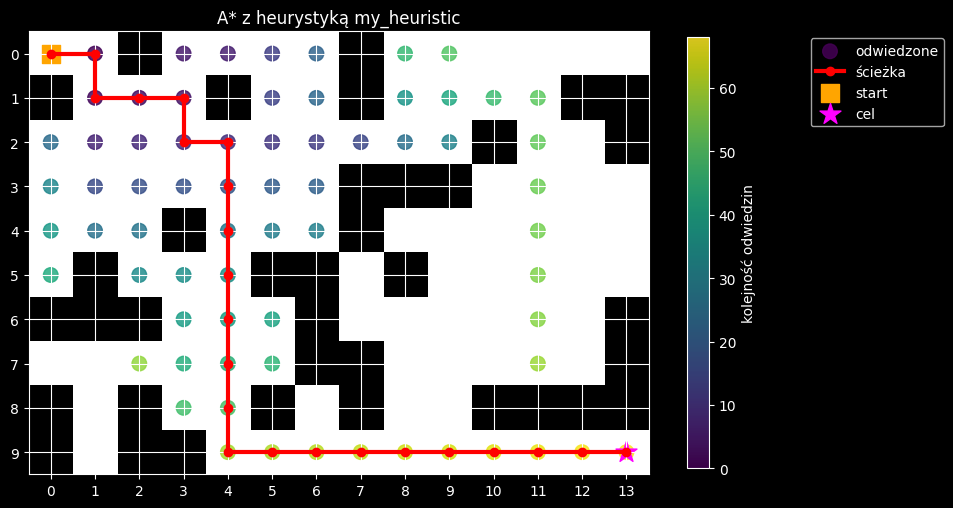

A* Manhattan
Koszt: 22
Odwiedzone stany: 46


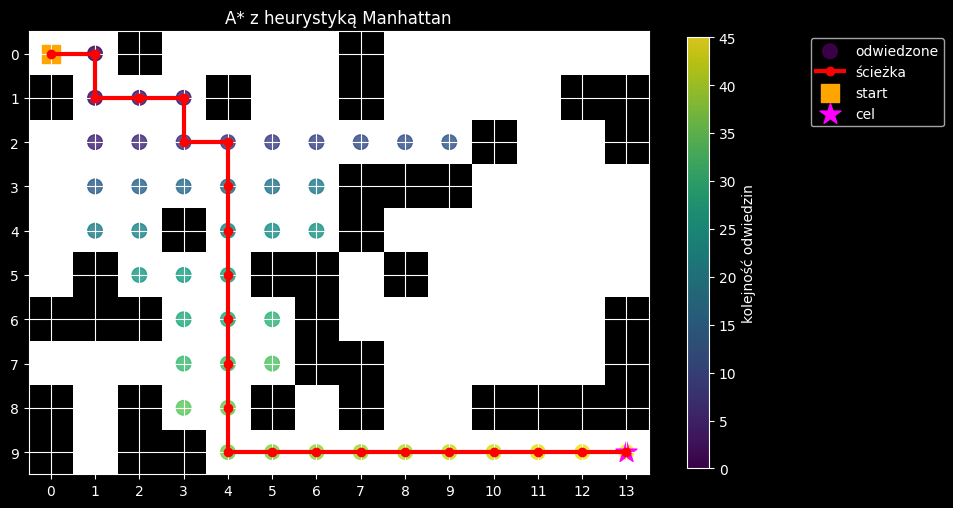

A* Euclidean
Koszt: 22
Odwiedzone stany: 59


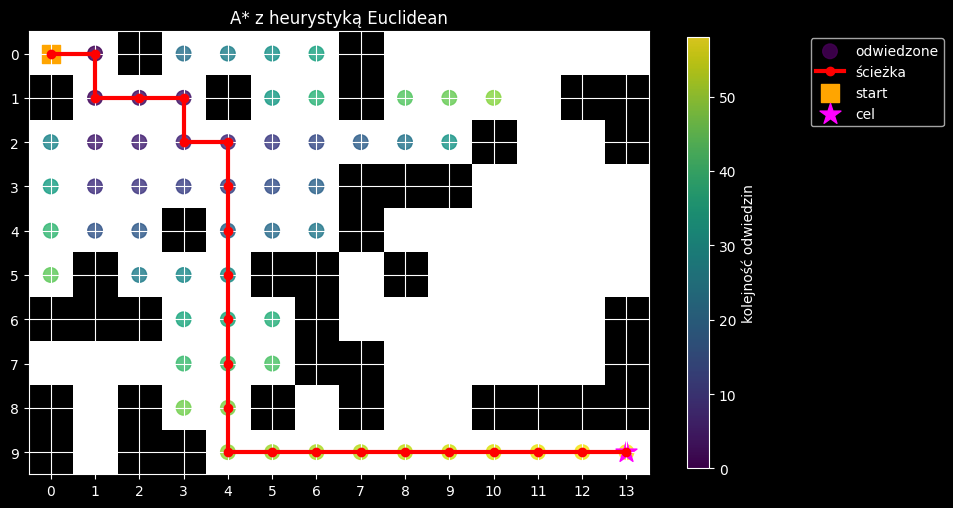

A* zero_heuristic
Koszt: 22
Odwiedzone stany: 103


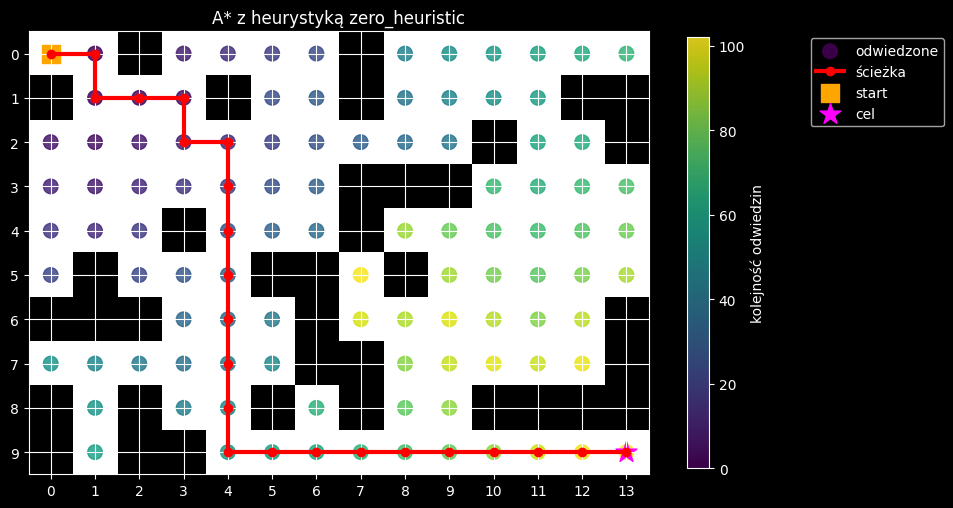

In [71]:
def my_heuristic(a, b):
    dx = abs(a[0] - b[0])
    dy = abs(a[1] - b[1])

    return max(dx, dy)


################################################## RESET


MAPA = [
    "..#....#......",
    "#...#..#....##",
    "..........#..#",
    ".......###....",
    "...#...#......",
    ".#...##.#.....",
    "###...#......#",
    "......##.....#",
    "#.#..#.#..####",
    "#.##..........",
]

grid = [[1 if ch == "#" else 0 for ch in wiersz] for wiersz in MAPA]

start = (0, 0)
goal = (9, 13)

rows = len(grid)
cols = len(grid[0])

print("Rozmiar planszy:", rows, "x", cols)
print("Start:", start)
print("Cel:", goal)

################################################## RESET

def astar(start, goal, heuristic):
    open_heap = []
    heapq.heappush(open_heap, (heuristic(start, goal), start))

    g_score = {start: 0}
    parent = {start: None}
    closed = set()
    visit_order = []

    while open_heap:
        _, current = heapq.heappop(open_heap)

        if current in closed:
            continue

        closed.add(current)
        visit_order.append(current)

        if current == goal:
            return reconstruct_path(parent, goal), visit_order, g_score[goal]

        for neighbor in get_neighbors(current):
            if neighbor in closed:
                continue  # stan zamknięty – nie zmieniamy już jego rodzica ani kosztu

            tentative_g = g_score[current] + 1

            if tentative_g < g_score.get(neighbor, float("inf")):
                parent[neighbor] = current
                g_score[neighbor] = tentative_g

                f_score = tentative_g + heuristic(neighbor, goal)

                heapq.heappush(
                    open_heap,
                    (f_score, neighbor)
                )

    return None, visit_order, float("inf")

##### pętla do zapamitania #################################################################

heurystyki = {
    "my_heuristic": my_heuristic,
    "Manhattan": manhattan,
    "Euclidean": euclidean,
    "zero_heuristic": zero_heuristic
}

for nazwa, h in heurystyki.items():

    path, visited, cost = astar(
        start,
        goal,
        heuristic=h
    )

    print(f"A* {nazwa}")
    print("Koszt:", cost)
    print("Odwiedzone stany:", len(visited))

    draw_grid(
        path,
        visited,
        f"A* z heurystyką {nazwa}"
    )

In [ ]:
################################################## ZADANIE 4

A* Manhattan
Koszt: 14
Odwiedzone stany: 18


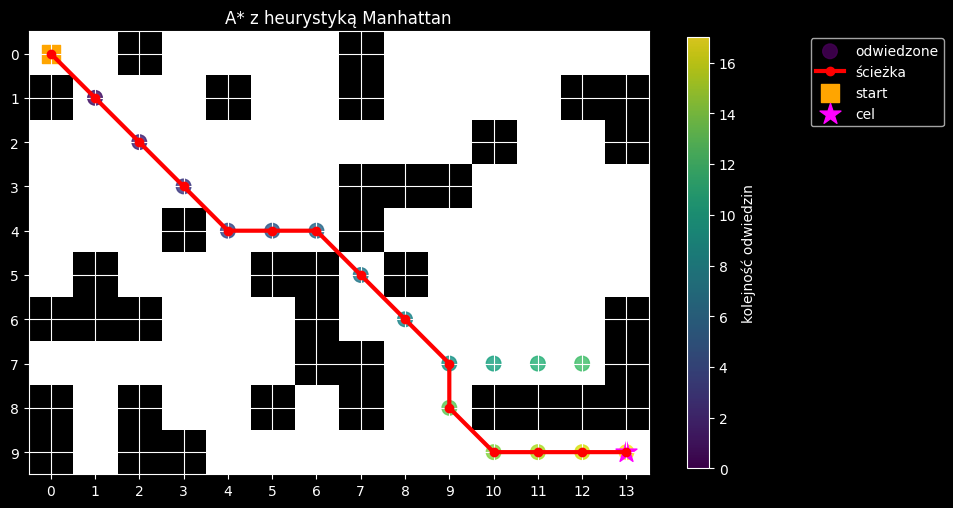

A* Euclidean
Koszt: 14
Odwiedzone stany: 18


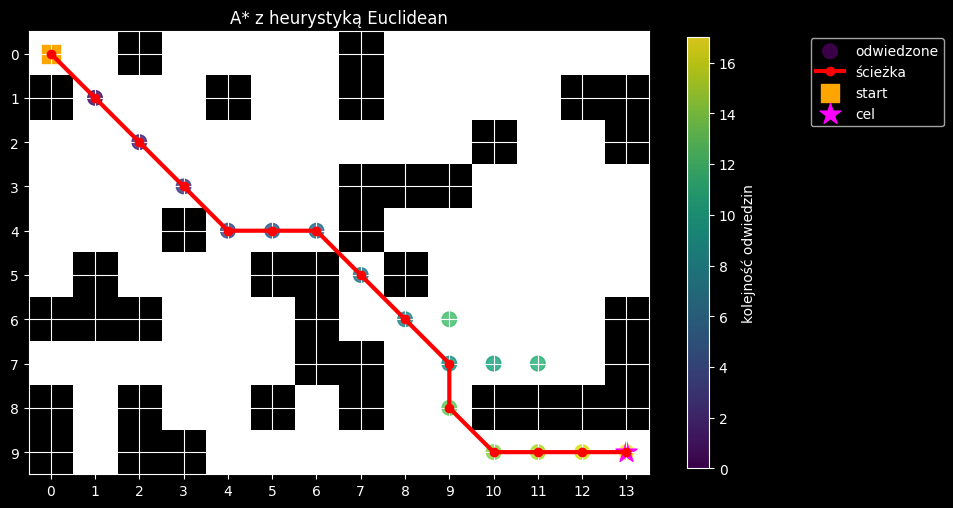

A* my_heuristic
Koszt: 14
Odwiedzone stany: 47


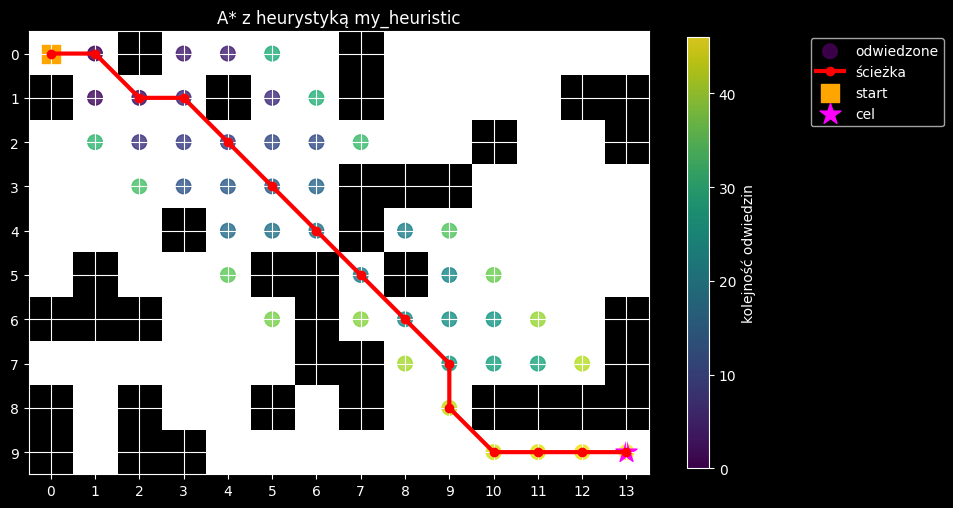

A* zero_heuristic
Koszt: 14
Odwiedzone stany: 103


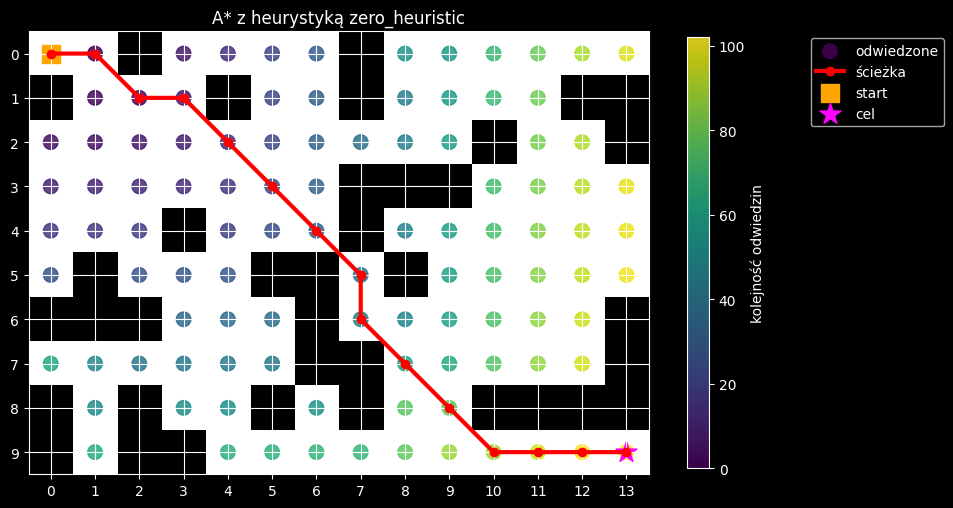

In [72]:
def get_neighbors(state):
    r, c = state

    moves = [
        (-1, 0),   # góra
        (1, 0),    # dół
        (0, -1),   # lewo
        (0, 1),    # prawo
        (-1, -1),  # góra-lewo
        (-1, 1),   # góra-prawo
        (1, -1),   # dół-lewo
        (1, 1),    # dół-prawo
    ]

    neighbors = []

    for dr, dc in moves:
        nr, nc = r + dr, c + dc

        if 0 <= nr < rows and 0 <= nc < cols:
            if grid[nr][nc] == 0:
                neighbors.append((nr, nc))

    return neighbors

def astar(start, goal, heuristic):
    open_heap = []
    heapq.heappush(open_heap, (heuristic(start, goal), start))

    g_score = {start: 0}
    parent = {start: None}
    closed = set()
    visit_order = []

    while open_heap:
        _, current = heapq.heappop(open_heap)

        if current in closed:
            continue

        closed.add(current)
        visit_order.append(current)

        if current == goal:
            return reconstruct_path(parent, goal), visit_order, g_score[goal]

        for neighbor in get_neighbors(current):
            if neighbor in closed:
                continue  # stan zamknięty – nie zmieniamy już jego rodzica ani kosztu

            tentative_g = g_score[current] + 1

            if tentative_g < g_score.get(neighbor, float("inf")):
                parent[neighbor] = current
                g_score[neighbor] = tentative_g

                f_score = tentative_g + heuristic(neighbor, goal)

                heapq.heappush(
                    open_heap,
                    (f_score, neighbor)
                )

    return None, visit_order, float("inf")

##### pętla do zapamitania #################################################################

heurystyki = {
    "Manhattan": manhattan,
    "Euclidean": euclidean,
    "my_heuristic": my_heuristic,
    "zero_heuristic": zero_heuristic
}

for nazwa, h in heurystyki.items():

    path, visited, cost = astar(
        start,
        goal,
        heuristic=h
    )

    print(f"A* {nazwa}")
    print("Koszt:", cost)
    print("Odwiedzone stany:", len(visited))

    draw_grid(
        path,
        visited,
        f"A* z heurystyką {nazwa}"
    )

A* my_heuristic
Koszt: 17.313708498984763
Odwiedzone stany: 63


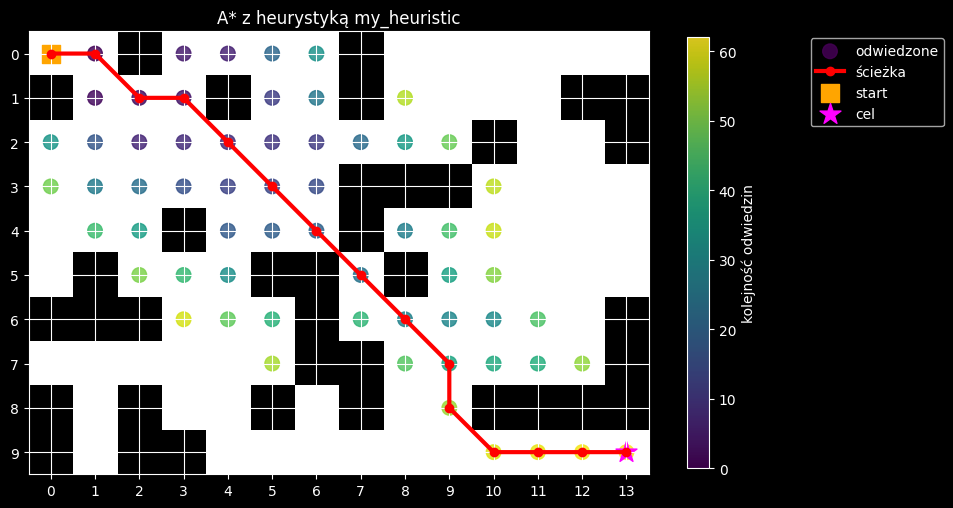

A* Manhattan
Koszt: 17.313708498984763
Odwiedzone stany: 18


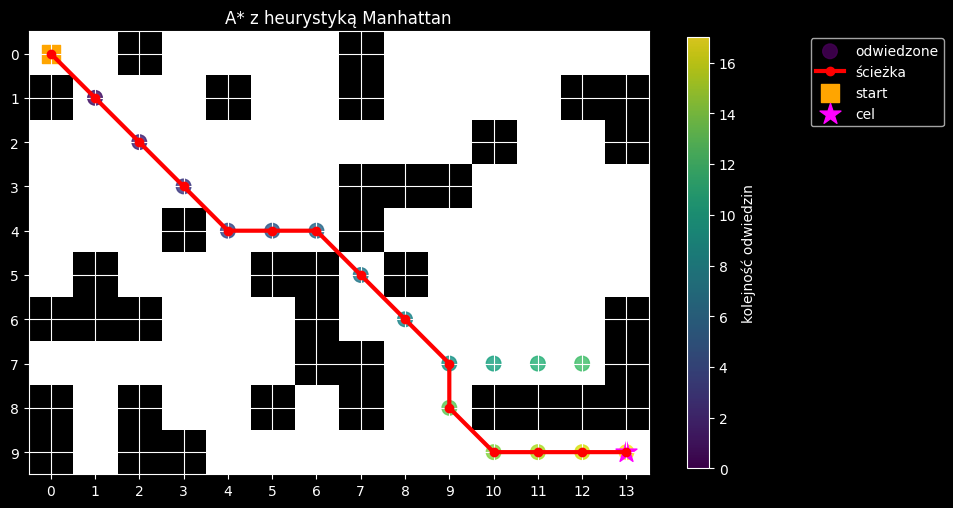

A* Euclidean
Koszt: 17.313708498984763
Odwiedzone stany: 43


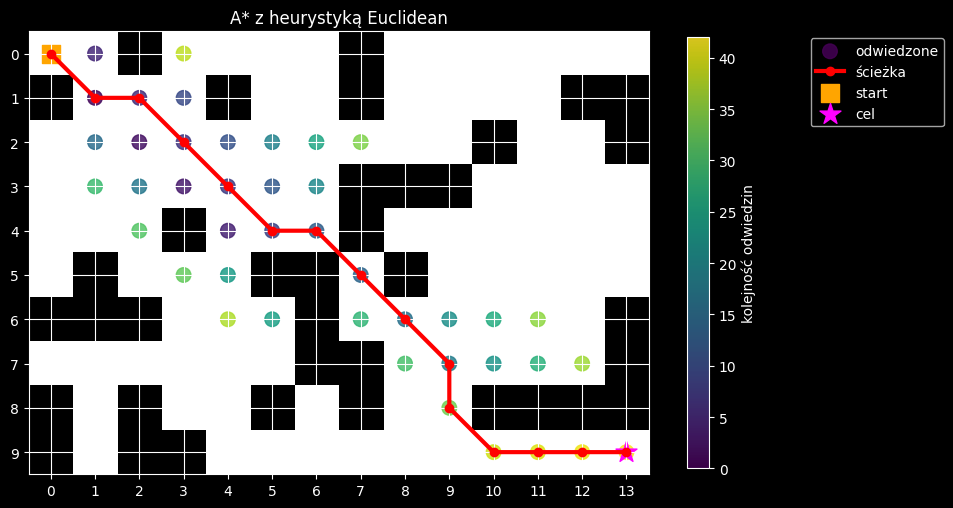

A* zero_heuristic
Koszt: 17.313708498984763
Odwiedzone stany: 103


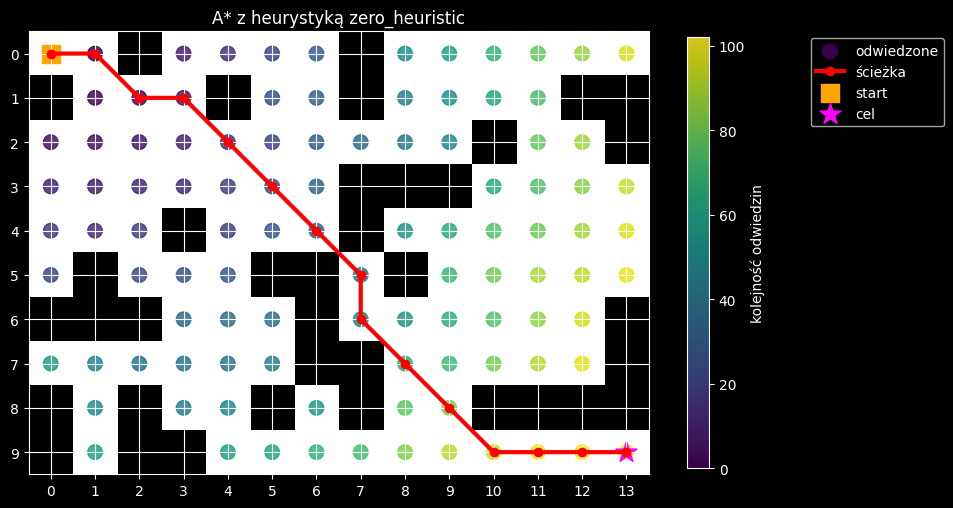

In [73]:
def get_neighbors(state):
    r, c = state

    moves = [
        (-1, 0),   # góra
        (1, 0),    # dół
        (0, -1),   # lewo
        (0, 1),    # prawo
        (-1, -1),  # góra-lewo
        (-1, 1),   # góra-prawo
        (1, -1),   # dół-lewo
        (1, 1),    # dół-prawo
    ]

    neighbors = []

    for dr, dc in moves:
        nr, nc = r + dr, c + dc

        if 0 <= nr < rows and 0 <= nc < cols:
            if grid[nr][nc] == 0:
                neighbors.append((nr, nc))

    return neighbors

def astar(start, goal, heuristic):
    open_heap = []
    heapq.heappush(open_heap, (heuristic(start, goal), start))

    g_score = {start: 0}
    parent = {start: None}
    closed = set()
    visit_order = []

    while open_heap:
        _, current = heapq.heappop(open_heap)

        if current in closed:
            continue

        closed.add(current)
        visit_order.append(current)

        if current == goal:
            return reconstruct_path(parent, goal), visit_order, g_score[goal]

        for neighbor in get_neighbors(current):
            if neighbor in closed:
                continue  # stan zamknięty – nie zmieniamy już jego rodzica ani kosztu

            diagonal = (
                current[0] != neighbor[0] and
                current[1] != neighbor[1]
            )


            cost = math.sqrt(2) if diagonal else 1


            tentative_g = g_score[current] + cost

            if tentative_g < g_score.get(neighbor, float("inf")):
                parent[neighbor] = current
                g_score[neighbor] = tentative_g

                f_score = tentative_g + heuristic(neighbor, goal)

                heapq.heappush(
                    open_heap,
                    (f_score, neighbor)
                )

    return None, visit_order, float("inf")

##### pętla do zapamitania #################################################################

heurystyki = {
    "my_heuristic": my_heuristic,
    "Manhattan": manhattan,
    "Euclidean": euclidean,
    "zero_heuristic": zero_heuristic
}

for nazwa, h in heurystyki.items():

    path, visited, cost = astar(
        start,
        goal,
        heuristic=h
    )

    print(f"A* {nazwa}")
    print("Koszt:", cost)
    print("Odwiedzone stany:", len(visited))

    draw_grid(
        path,
        visited,
        f"A* z heurystyką {nazwa}"
    )

In [ ]:
"""
1.Czy Manhattan nadal jest najlepszym wyborem?
Tak. Odwiedził mniej stanów.
2. Jaką heurystykę zastosować?
Na aktualnej mapie Manhattan działa najlepiej.
3. Co się zmieni, jeśli koszt ruchu po przekątnej będzie równy $\sqrt{2}$?
Koszt i odwiedzone stany uległy zmianie :
Koszt dla wszystkich heurystyk : 14 -> ~17
Liczba odwiedzonych stanów w heurystyce Euclidean jest ponad dwa razy większa (18 -> 43) a huerystyka Manhattan nie uległa zmianie (wciąż 18).
"""

In [ ]:
################################################## ZADANIE 5

Rozmiar planszy: 10 x 14
Start: (0, 0)
Cel: (9, 13)
A* - koszt: 24
A* - odwiedzone stany: 47


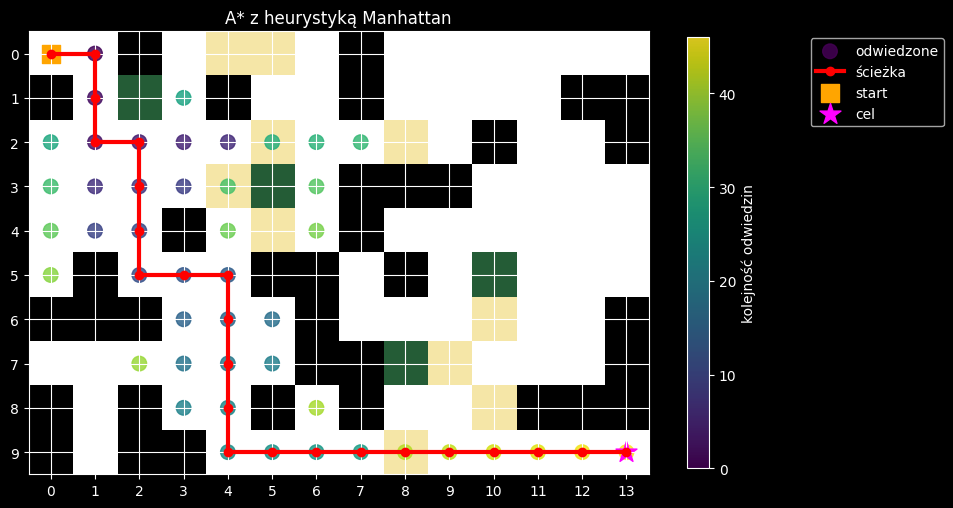

BFS - koszt ścieżki: 24
BFS - odwiedzone stany: 104


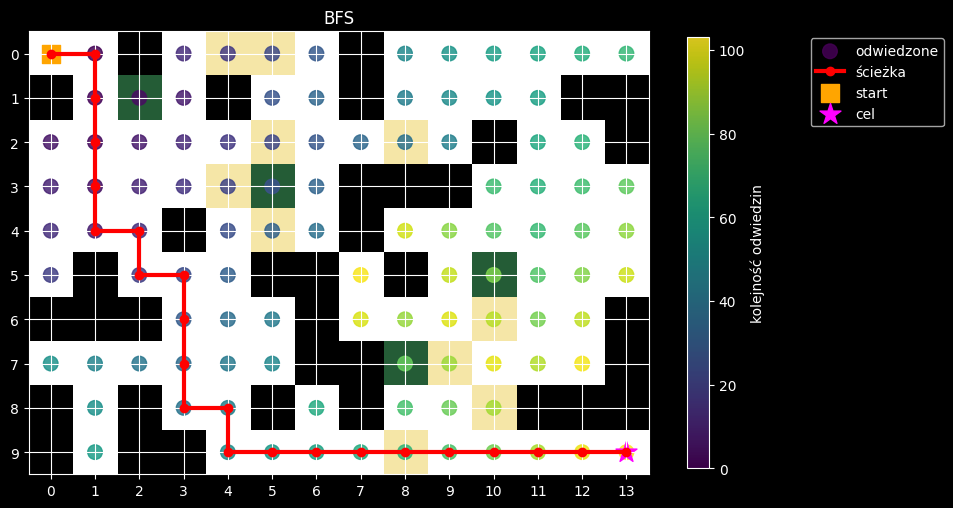

In [88]:
MAPA = [
    "..#.SS.#......",
    "#.B.#..#....##",
    ".....S..S.#..#",
    "....SB.###....",
    "...#.S.#......",
    ".#...##.#.B...",
    "###...#...S..#",
    "......##BS...#",
    "#.#..#.#..S###",
    "#.##....S.....",
]

teren = {
    ".": 0,  # zwykłe pole
    "#": 1,  # przeszkoda
    "S": 3,  # piasek
    "B": 5   # bagno
}

grid = [[teren[ch] for ch in wiersz] for wiersz in MAPA]

start = (0, 0)
goal = (9, 13)

rows = len(grid)
cols = len(grid[0])

print("Rozmiar planszy:", rows, "x", cols)
print("Start:", start)
print("Cel:", goal)


################################################## RESET

def get_neighbors(state):
    r, c = state

    moves = [
        (-1, 0),  # góra
        (1, 0),   # dół
        (0, -1),  # lewo
        (0, 1),   # prawo
    ]

    neighbors = []

    for dr, dc in moves:
        nr, nc = r + dr, c + dc

        if 0 <= nr < rows and 0 <= nc < cols:
            if grid[nr][nc] != 1:
                neighbors.append((nr, nc))

    return neighbors

################################################## RESET

koszty = {
    0: 1,  # zwykłe pole
    3: 3,  # piasek
    5: 5   # bagno
}

def astar(start, goal, heuristic=manhattan):
    open_heap = []
    heapq.heappush(open_heap, (heuristic(start, goal), start))

    g_score = {start: 0}
    parent = {start: None}
    closed = set()
    visit_order = []

    while open_heap:
        _, current = heapq.heappop(open_heap)

        if current in closed:
            continue

        closed.add(current)
        visit_order.append(current)

        if current == goal:
            return reconstruct_path(parent, goal), visit_order, g_score[goal]

        for neighbor in get_neighbors(current):
            if neighbor in closed:
                continue  # stan zamknięty – nie zmieniamy już jego rodzica ani kosztu

            nr, nc = neighbor
            tentative_g = g_score[current] + koszty[grid[nr][nc]]

            if tentative_g < g_score.get(neighbor, float("inf")):
                parent[neighbor] = current
                g_score[neighbor] = tentative_g

                f_score = tentative_g + heuristic(neighbor, goal)

                heapq.heappush(
                    open_heap,
                    (f_score, neighbor)
                )

    return None, visit_order, float("inf")


astar_path, astar_visited, astar_cost = astar(start, goal)

print("A* - koszt:", astar_cost)
print("A* - odwiedzone stany:", len(astar_visited))

draw_grid(astar_path, astar_visited, "A* z heurystyką Manhattan")

def reconstruct_path(parent, goal):
    path = []
    current = goal

    while current is not None:
        path.append(current)
        current = parent[current]

    path.reverse()
    return path


def bfs(start, goal):
    queue = deque([start])
    visited = {start}
    parent = {start: None}
    visit_order = []

    while queue:
        current = queue.popleft()
        visit_order.append(current)

        if current == goal:
            return reconstruct_path(parent, goal), visit_order

        for neighbor in get_neighbors(current):
            if neighbor not in visited:
                visited.add(neighbor)
                parent[neighbor] = current
                queue.append(neighbor)

    return None, visit_order


bfs_path, bfs_visited = bfs(start, goal)

if bfs_path is not None:

    bfs_cost = sum(
        koszty[grid[r][c]]
        for r, c in bfs_path[1:]
    )

    print("BFS - koszt ścieżki:", bfs_cost)
    print("BFS - odwiedzone stany:", len(bfs_visited))

    draw_grid(bfs_path, bfs_visited, "BFS")




In [ ]:
################################################## ZADANIE 6

In [89]:
"""
W algorytmie A* wzór na obliczenie kosztu danej scieżki to f(n) = g(n) + h(n)
Gdzie :
f(n) to koszt całkowity ścieżki
g(n) to koszt od startu do aktualnej pozycji w której jest obliczany koszt
h(n) to koszt który jest obliczany za pomocą heurystyki od aktualnej pozycji do celu
Inaczej :
g(n) - koszt od startu do aktualnego miejscac
h(n) - szacowany koszt od aktualnego miejsca do celu
"""

'\nW algorytmie A* wzór na obliczenie kosztu danej scieżki to f(n) = g(n) + h(n)\nGdzie :\n'